In [10]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
import os

In [11]:
load_dotenv()

True

In [12]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str
    

In [13]:
parent_llm = ChatGoogleGenerativeAI(model='gemini-3.5-flash-lite',google_api_key=os.getenv("GEMINI_API_KEY_"))
subgraph_llm = ChatGoogleGenerativeAI(model='gemini-3.5-flash-lite',google_api_key=os.getenv("GEMINI_API_KEY_5"))

In [14]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'answer_hin': translated_text[0]['text']}

In [15]:
subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [16]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer[0]['text']}

In [17]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", subgraph)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

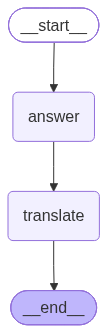

In [18]:
graph = parent_builder.compile()

graph

In [19]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'answer_eng': '**Quantum physics** (also known as quantum mechanics) is the branch of science that studies the universe at the smallest scales—at the level of atoms and subatomic particles (like electrons, protons, and photons).\n\nWhile classical physics (the physics of everyday life, like gravity and motion) explains how large things work, quantum physics explains how the building blocks of the universe behave, and they often follow very strange, counterintuitive rules.\n\nHere are the core concepts that make quantum physics different:\n\n1. **Quantization:** Unlike everyday energy, which flows in a continuous stream, energy at the quantum level comes in discrete, indivisible packets called "quanta" (singular: *quantum*). \n2. **Wave-Particle Duality:** Tiny particles like electrons can act sometimes like solid little balls (particles) and other times like ripples in water (waves). \n3. **Superposition:** A quantum particle can exist in multip